# create_agent 실습: 대출 문의 에이전트에 양식과 실행 정보 붙이기

**이 노트북에서 할 일**

1. 01절 에이전트 그래프에 02절 도구 전략과 03절 실행 정보를 붙여, 자료실 문의 하나를 처리합니다.
2. 두 도구의 도구 메시지와 칸 `structured_response`로, 붙인 부품이 흐름 안에서 쓰였는지 셉니다.
3. 실행 정보의 연체 일수 하나만 바꿔 다시 실행하고, 두 실행을 견줍니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델은 `gpt-5.4-mini`이고, 교재 출력에서 모델 요청은 모두 4번입니다.
6절 실행 1에서 2번, 7절 실행 2에서 2번을 보냈습니다.
모델이 두 도구를 따로 부르면 실행마다 3번이 되어, 모두 6번까지 늘 수 있습니다.
요금표로 어림한 예상 비용은 0.01달러 아래이고, 청구 금액이 아닙니다.

도구는 노트북 안 규정 딕셔너리와 실행 정보를 읽기만 하고, 읽는 파일과 새로 쓰는 파일은 없습니다.
06절이 쓴 비교 기록 파일(`data/rag-comparison.json`)도 이 절은 읽지 않습니다.
앞에서 배운 함수 다섯은 도구 파일 `runner_tools.py`에서 가져옵니다.
걸린 시간은 재지 않습니다. 교재 출력을 만든 실행에서는 노트북 전체가 10초 안에 끝났습니다.

**기준 버전** — 첫 셀에서 패키지 일곱을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
langgraph 1.2.11과 numpy 2.5.3도 함께 설치합니다.
pydantic 2.13.5와 python-dotenv 1.2.3도 함께 설치합니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**실습 범위** — 이 절은 챕터 끝 실습 절이고 30분 안에 끝나는 분량입니다.
강사와 함께 첫 셀부터 차례로 실행하고, 따로 내는 과제는 없습니다.
01~06절에서 쓴 이름과 Ch 2에서 배운 문법만 씁니다.

실습 폴더 `labs/part6/ch21-create-agent`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 맨 위에 파란 상자 셋이 나란히 있습니다. 왼쪽은 01절 도구 lookup_policy 규정 글 하나를 찾음, 가운데는 02절 양식 클래스 LoanAnswer 도구 전략으로 감쌈, 오른쪽은 03절 도구 check_my_loan 실행 정보 형식 MemberContext입니다. 세 상자에서 화살표가 회색 상자 create_agent 한 번 tools response_format context_schema로 모이고, 그 상자에서 회색 상자 에이전트 그래프 노드 model tools로 화살표가 갑니다. 오른쪽 초록 상자 문의 하나 실행 정보 M-0317 overdue_days 0 또는 3에서 invoke 화살표가 에이전트 그래프로 가고, 에이전트 그래프에서 맨 아래 노란 상자 칸 structured_response 종류 LoanAnswer로 화살표가 가는 그림](attachment:07-1-세-절-부품을-붙인-에이전트-그래프.png)

위에서 아래로 읽습니다.
맨 위 파란 상자 셋은 01~03절에서 우리가 적은 부품이고, 모두 회색 상자 `create_agent` 한 번에 들어갑니다.
회색은 라이브러리가 준 함수와, 그 함수가 만든 에이전트 그래프입니다.
초록 상자는 메서드 `invoke`로 넘기는 문의와 실행 정보이고, 실행 2에서는 연체 일수만 바꿉니다.
맨 아래 노란 상자는 노트북 6·7절에서 출력으로 확인한 양식 값의 칸입니다.
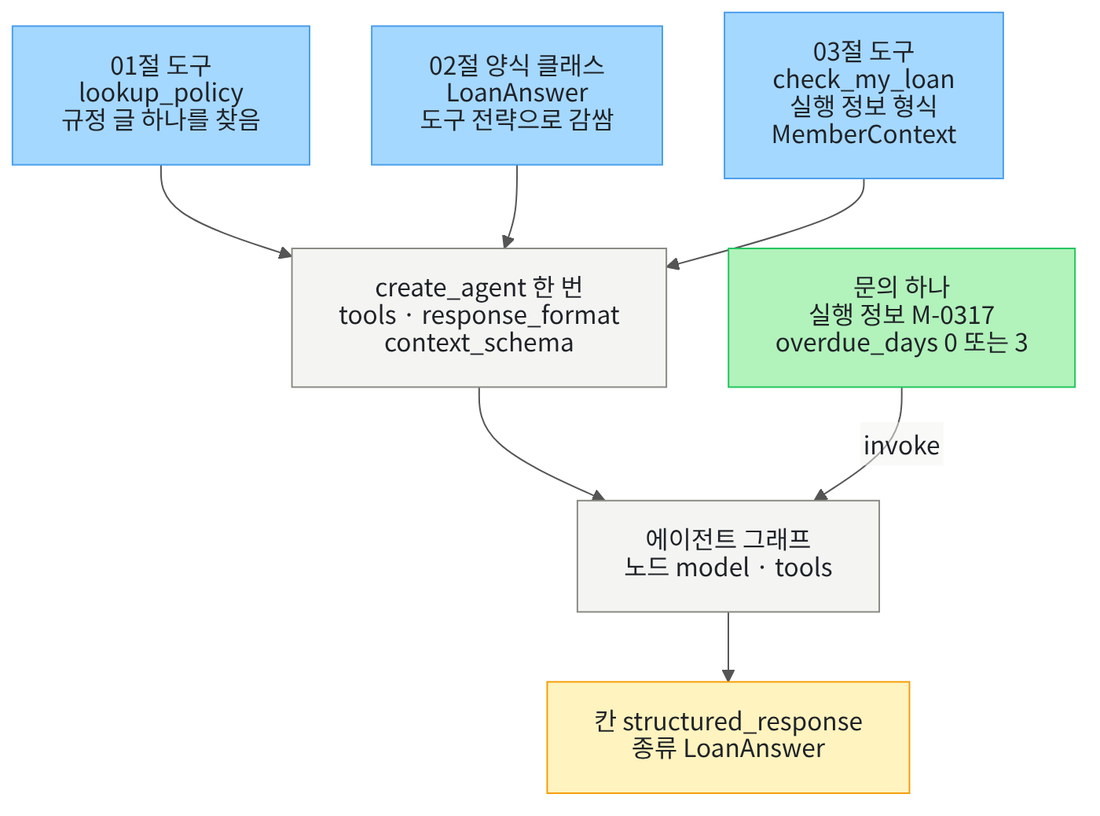

## 1. 준비

이번 절은 이 챕터의 실습입니다.
01절 에이전트 그래프에 02절 도구 전략과 03절 실행 정보를 붙여, 자료실 문의 하나를 처리합니다.
첫 셀은 패키지 일곱 개를 설치하고 설치된 판 번호를 출력합니다.
도구 파일이 NumPy를 쓰므로, 01~06절처럼 numpy도 함께 설치합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "langgraph==1.2.11" "numpy==2.5.3" "pydantic==2.13.5" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("numpy:", version("numpy"))
print("pydantic:", version("pydantic"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
langgraph: 1.2.11
numpy: 2.5.3
pydantic: 2.13.5
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`·`langchain-core: 1.6.2`·`langchain-openai: 1.6.0`이 보입니다.
출력 줄 `langgraph: 1.2.11`·`numpy: 2.5.3`·`pydantic: 2.13.5`·`python-dotenv: 1.2.3`도 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
양식 클래스를 적는 이름과 도구 전략은 02절, 실행 정보 형식과 실행 객체 표시는 03절에서 가져온 이름입니다.
이 절에서 새로 가져오는 이름은 없습니다.

In [2]:
# 01~03절에서 쓴 이름을 가져옵니다(이 절에서 새로 가져오는 이름은 없음)
from typing import Literal
from typing_extensions import TypedDict

from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from langchain.tools import ToolRuntime, tool

# 앞에서 배운 함수는 도구 파일에서 가져옵니다
from runner_tools import agent_row, estimate_cost, print_branches, show_messages, sum_usage

print("01~03절에서 가져와 붙일 이름:", "create_agent", "ToolStrategy", "ToolRuntime")

01~03절에서 가져와 붙일 이름: create_agent ToolStrategy ToolRuntime


**결과 읽기** — 출력 줄 `01~03절에서 가져와 붙일 이름: create_agent ToolStrategy ToolRuntime`이 보입니다.

앞에서 배운 함수는 `runner_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

함수 `show_messages`는 Ch 19 06절, `sum_usage`는 Ch 19 05절, `estimate_cost`는 Ch 6 06절에서 배웠습니다.
함수 `agent_row`는 01절 10절, `print_branches`는 02절 6절에서 처음 적은 함수입니다.
이 절에서 도구 파일에 더한 함수는 없습니다.

## 2. 키와 모델 준비

모델은 01~06절과 같은 `gpt-5.4-mini`이고, 과정의 같은 설정으로 부릅니다.
이렇게 만든 모델 객체를 5절에서 조립하는 에이전트 그래프에 넘깁니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도, 모델이 도구를 부르는 방식과 답 글이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-25에 이 모델로 실행한 결과입니다.

## 3. 오늘 처리할 문의

이번 실습은 자료실 창구에 들어온 문의 하나를 처리합니다.
이용자는 지금 새 책을 빌릴 수 있는지와, 일반 도서 대출 규정을 함께 묻습니다.
앞의 물음은 03절 도구가, 뒤의 물음은 01절 도구가 답할 수 있는 물음입니다.
문의 글은 이 절에서 새로 정했고, 이용자 번호는 03절 7절 값 그대로입니다.

다음 셀은 두 값을 정하고 출처와 함께 출력합니다.
두 값 모두 실행 전에 정했습니다.

In [5]:
# 오늘 처리할 자료실 문의 하나와, 이 문의를 보낸 이용자 번호를 정합니다(실행 전에 정한 값)
inquiry = "제가 지금 새 책을 빌릴 수 있는지 확인해 주세요. 일반 도서 대출 규정도 함께 알려 주세요."
member_id = "M-0317"
print("문의:", inquiry)
print("문의 출처: 이 절에서 실행 전에 정한 글(두 도구가 모두 있어야 답할 수 있게)")
print("이용자 번호:", member_id)
print("이용자 번호 출처: 03절 7절 실행 정보 값 그대로")

문의: 제가 지금 새 책을 빌릴 수 있는지 확인해 주세요. 일반 도서 대출 규정도 함께 알려 주세요.
문의 출처: 이 절에서 실행 전에 정한 글(두 도구가 모두 있어야 답할 수 있게)
이용자 번호: M-0317
이용자 번호 출처: 03절 7절 실행 정보 값 그대로


**결과 읽기** — 출력 줄 `이용자 번호: M-0317`과 두 출처 줄로 오늘 쓸 값을 확인합니다.
문의 글은 실행 1과 실행 2에 똑같이 넣습니다.
두 실행에서 바꾸는 것은 실행 정보의 연체 일수 하나입니다.

## 4. 재료 · 두 도구와 양식 클래스

다음 셀은 01절 3절 셀과 글자까지 같은 코드로, 규정 딕셔너리를 만듭니다.

In [6]:
# 교육센터 자료실 규정 셋을, 주제어를 키로 한 딕셔너리에 담습니다(도구가 읽기만 하는 자료)
POLICIES = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
    "연체": "연체한 일수만큼 새 대출이 제한됩니다.",
}
topics = list(POLICIES.keys())
print("규정 주제어:", topics)

규정 주제어: ['대출', '운영', '연체']


**결과 읽기** — 출력 줄 `규정 주제어: ['대출', '운영', '연체']`로 키 셋을 확인합니다.
오늘 문의의 뒤 물음은 키 `대출`의 글로 답할 수 있습니다.

다음 셀도 01절 3절 도구 셀과 글자까지 같은 코드입니다.

In [7]:
# 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다(맨 @tool 줄 — Ch 19 01절)
@tool
def lookup_policy(topic: str):
    """교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 운영, 연체 가운데 하나를 넣습니다."""
    # 딕셔너리에 없는 주제어면 오류를 냅니다(이 오류를 그래프 안에서 다루는 법은 Ch 20 02절에서 보았습니다)
    if topic not in POLICIES:
        raise ValueError("지원하지 않는 주제: " + topic)
    return POLICIES[topic]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
매개변수 `topic`은 모델이 도구 호출 요청의 인자로 채우는 값입니다.

다음 셀은 03절 5절과 글자까지 같은 실행 정보 형식입니다.
실행할 때 인자 `context`로 넘길 딕셔너리의 칸을 적습니다.

In [8]:
# 실행할 때 상태 밖으로 넘길 값(실행 정보)의 칸을 적습니다(Ch 13 상태 형식과 같은 모양)
class MemberContext(TypedDict):
    # 이용자 번호와, 지금까지 연체한 일수입니다
    member_id: str
    overdue_days: int

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸은 이용자 번호 `member_id`와 연체 일수 `overdue_days` 둘입니다.
실행 2에서는 이 가운데 연체 일수 하나만 바꿉니다.

다음 셀도 03절 5절과 글자까지 같은 도구 셀입니다.
매개변수 `runtime`에 붙은 실행 객체 표시를 보고, 라이브러리가 실행 정보를 넣어 줍니다.

In [9]:
# 실행 정보에서 이용자 번호와 연체 일수를 읽어, 새 대출을 할 수 있는지 알려 주는 도구를 만듭니다
@tool
def check_my_loan(runtime: ToolRuntime[MemberContext]):
    """자료실 이용자 본인이 지금 새 책을 빌릴 수 있는지 확인합니다."""
    # 실행 정보는 딕셔너리로 넘어오므로 키로 꺼냅니다
    member = runtime.context["member_id"]
    days = runtime.context["overdue_days"]
    if days == 0:
        return "이용자 " + member + ": 연체가 없어 새 대출을 할 수 있습니다."
    # 연체가 있으면 3절 규정 딕셔너리의 연체 규정 글을 붙입니다
    return "이용자 " + member + ": 연체 " + str(days) + "일. " + POLICIES["연체"]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
연체 일수가 0이면 새 대출을 할 수 있다는 글을 내놓습니다.
0이 아니면 연체 규정 글을 붙인 글을 내놓습니다.
매개변수 `runtime`이 도구 명세에 실리지 않는 것은 03절 5절에서 보았습니다.

다음 셀은 문의의 처리 결과를 담을 양식 클래스를 적습니다.
02절 4절 양식 클래스 `PolicyAnswer`와 같은 모양이고, 칸만 이 문의에 맞게 바꿨습니다.
02절 판은 주제어 칸과 답 칸이라, 새 대출을 할 수 있는지를 담을 칸이 없기 때문입니다.
칸 `can_borrow`에는 Ch 19 02절처럼 `Literal`로 두 값만 적을 수 있게 했습니다.

In [10]:
# 문의 하나의 처리 결과를 담을 양식 클래스를 적습니다(칸 둘: 새 대출 가능 여부와 한두 문장 답)
class LoanAnswer(BaseModel):
    # 새 대출 가능 여부 칸에는 괄호 안 두 값 가운데 하나만 적을 수 있습니다(Ch 19 02절 Literal)
    can_borrow: Literal["가능", "불가"] = Field(description="check_my_loan 도구 결과로 본, 지금 새 책을 빌릴 수 있는지")
    answer: str = Field(description="두 도구 결과에 근거한 한두 문장 답")

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 양식 클래스는 5절에서 도구 전략 `ToolStrategy`로 감싸 에이전트 그래프에 넘깁니다.

다음 셀은 02절 4절처럼 양식 클래스를 JSON 모양 설명으로 바꿔 봅니다.

In [11]:
# 양식 클래스를 JSON 모양 설명으로 바꿔, 꼭 채울 칸과 새 대출 가능 여부 칸의 값을 봅니다(02절 4절)
answer_form = LoanAnswer.model_json_schema()
print("꼭 채울 칸:", answer_form["required"])
borrow_form = answer_form["properties"]["can_borrow"]
borrow_values = borrow_form["enum"]
print("새 대출 가능 여부 칸의 고를 수 있는 값:", borrow_values)

꼭 채울 칸: ['can_borrow', 'answer']
새 대출 가능 여부 칸의 고를 수 있는 값: ['가능', '불가']


**결과 읽기** — 출력 줄 `꼭 채울 칸: ['can_borrow', 'answer']`로 칸 둘을 확인합니다.
출력 줄 `새 대출 가능 여부 칸의 고를 수 있는 값: ['가능', '불가']`는 `Literal`에 적은 두 값입니다.
이 목록 `borrow_values`는 6·7절에서 양식 칸 값을 확인할 때 씁니다.

## 5. 조립 · create_agent 한 번에 세 절의 부품 넣기

조립은 함수 `create_agent`를 한 번 부르는 일입니다.
01절에서 넘긴 모델·도구 목록·시스템 메시지 글에, 인자 둘을 더합니다.
인자 `response_format`에는 02절 도구 전략을, 인자 `context_schema`에는 03절 실행 정보 형식을 넘깁니다.
시스템 메시지 글은 01절 글 뒤에 03절 글의 둘째 문장을 이었습니다.
셀의 줄 끝 주석에 부품마다 어느 절에서 왔는지 적었습니다.

In [12]:
# 01절 에이전트 그래프에 02절 도구 전략과 03절 도구·실행 정보 형식을 붙여 조립합니다(요청은 아직 보내지 않음)
system_text = "교육센터 자료실 안내 도우미입니다. 자료실 규정을 묻는 질문에는 lookup_policy 도구로 찾은 규정 글에 근거해 답하세요. 이용자가 지금 새 책을 빌릴 수 있는지 물으면 check_my_loan 도구로 확인한 결과에 근거해 답하세요."
answer_format = ToolStrategy(LoanAnswer)
agent = create_agent(
    model,
    tools=[lookup_policy, check_my_loan],  # 01절 도구와 03절 도구
    system_prompt=system_text,  # 01절 글 뒤에 03절 글의 둘째 문장
    response_format=answer_format,  # 02절 도구 전략
    context_schema=MemberContext,  # 03절 실행 정보 형식
)
print("만든 것의 종류:", type(agent).__name__)

만든 것의 종류: CompiledStateGraph


**결과 읽기** — 출력 줄 `만든 것의 종류: CompiledStateGraph`로, 01~03절과 같은 종류의 그래프입니다.
이 줄에서도 모델 요청은 나가지 않습니다.

다음 셀은 조립한 그래프의 노드와 조건 함수, 상태 칸을 봅니다.

In [13]:
# 조립한 그래프의 노드·조건 함수·상태 칸을 봅니다(02절 함수 print_branches — 도구 파일)
print("등록된 노드:", list(agent.builder.nodes))
print_branches(agent)
print("상태 칸:", list(agent.builder.channels))

등록된 노드: ['model', 'tools']
tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model', '__end__']
model | 조건 함수: model_to_tools | 갈 수 있는 곳: ['tools', '__end__', 'model']
상태 칸: ['messages', 'jump_to', 'structured_response']


**결과 읽기** — 출력 줄 `등록된 노드: ['model', 'tools']`는 01절과 같습니다.
출력 줄 `tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model', '__end__']`는 02절 도구 전략 그래프와 같습니다.
출력 줄 `model | 조건 함수: model_to_tools | 갈 수 있는 곳: ['tools', '__end__', 'model']`도 02절과 같습니다.
출력 줄 `상태 칸: ['messages', 'jump_to', 'structured_response']`에는 실행 정보의 칸이 없습니다.
03절에서 본 것처럼, 실행 정보 형식은 상태 칸이 되지 않습니다.

## 6. 실행 1 · 연체 0일

실행 1은 연체 0일인 실행 정보로 문의를 보냅니다.
실행 전에 예상해 봅니다.
모델이 두 도구를 부르고, 도구 결과를 받은 뒤 양식 도구를 부를 것입니다.
두 도구를 한 응답에 함께 부르면 모델 요청은 2번이고, 따로 부르면 3번일 것입니다.

In [14]:
# 실행 1: 연체 0일인 실행 정보로 문의를 보냅니다(모델 노드를 지날 때마다 모델 요청 1번)
one_context = {"member_id": member_id, "overdue_days": 0}
print("실행 1의 실행 정보:", one_context, "| 출처: 03절 7절 값 그대로")
one_state = {"messages": [HumanMessage(content=inquiry)]}
one_result = agent.invoke(one_state, context=one_context)
one_keys = list(one_result.keys())
print("결과 딕셔너리의 키:", one_keys)
print("메시지 칸의 메시지 수:", len(one_result["messages"]))

실행 1의 실행 정보: {'member_id': 'M-0317', 'overdue_days': 0} | 출처: 03절 7절 값 그대로


결과 딕셔너리의 키: ['messages', 'structured_response']
메시지 칸의 메시지 수: 6


**결과 읽기** — 출력 줄 `결과 딕셔너리의 키: ['messages', 'structured_response']`에 양식 값의 칸이 있습니다.
출력 줄 `메시지 칸의 메시지 수: 6`은 01절 대출 질문의 넷보다 둘 많습니다.
넘긴 실행 정보는 결과 딕셔너리의 키에 없습니다.

다음 셀은 메시지 칸을 차례로 출력합니다.

In [15]:
# 메시지 칸을 차례로 출력합니다(Ch 19 06절 함수 show_messages)
print("메시지 칸:")
show_messages(one_result["messages"])

메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['check_my_loan', 'lookup_policy']
ToolMessage | 결과 상태: success | 내용: 이용자 M-0317: 연체가 없어 새 대출을 할 수 있습니다.
ToolMessage | 결과 상태: success | 내용: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
AIMessage | 도구 호출 요청: ['LoanAnswer']
ToolMessage | 결과 상태: success | 내용: Returning structured response: can_borrow='가능' answer='현재 연체가 없어 새 책을 빌릴 수 있습니다. 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.'


**결과 읽기** — 라벨 줄 `메시지 칸:` 아래 여섯 줄입니다.
둘째 줄 `AIMessage | 도구 호출 요청: ['check_my_loan', 'lookup_policy']`에서 모델이 두 도구를 한 응답에 불렀습니다.
셋째 줄 도구 메시지의 내용은 `이용자 M-0317: 연체가 없어 새 대출을 할 수 있습니다.`입니다.
넷째 줄 도구 메시지의 내용은 01절 도구가 찾은 대출 규정 글입니다.
다섯째 줄 응답은 양식 도구를 불렀고, 여섯째 줄이 그 요청에 붙은 도구 메시지입니다.

다음 셀은 응답마다 도구 호출 요청의 이름과 인자를 봅니다.
01절 8절에서 규정 두 가지를 묻는 질문을 볼 때 쓴 셀과 같은 모양입니다.

In [16]:
# 응답마다 도구 호출 요청의 이름과 인자를 차례로 봅니다(01절 8절 셀과 같은 모양)
for message in one_result["messages"]:
    if type(message).__name__ == "AIMessage":
        print("응답 | 도구 호출 요청 수:", len(message.tool_calls))
        for call in message.tool_calls:
            print("  도구 이름:", call["name"], "| 인자:", call["args"])

응답 | 도구 호출 요청 수: 2
  도구 이름: check_my_loan | 인자: {}
  도구 이름: lookup_policy | 인자: {'topic': '대출'}
응답 | 도구 호출 요청 수: 1
  도구 이름: LoanAnswer | 인자: {'can_borrow': '가능', 'answer': '현재 연체가 없어 새 책을 빌릴 수 있습니다. 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.'}


**결과 읽기** — 첫 응답은 `응답 | 도구 호출 요청 수: 2`이고, 도구 `check_my_loan`의 인자는 `{}`입니다.
같은 응답의 도구 `lookup_policy` 인자는 `{'topic': '대출'}`입니다.
둘째 응답은 `응답 | 도구 호출 요청 수: 1`이고, 도구 이름 `LoanAnswer`의 인자에 양식 값이 담겼습니다.
이 인자는 도구 메시지 둘을 받은 뒤의 요청에서 나왔습니다.

양식 도구 인자의 답 칸 글은 모델이 쓴 글이라 실행마다 달라질 수 있습니다.

다음 셀은 칸 `structured_response`에 담긴 양식 값을 봅니다.

In [17]:
# 칸 structured_response에 담긴 양식 값의 종류와 새 대출 가능 여부 칸을 봅니다
one_answer = one_result["structured_response"]
print("structured_response의 종류:", type(one_answer).__name__)
print("새 대출 가능 여부 칸:", one_answer.can_borrow)
print("정해 둔 두 값 안인가:", one_answer.can_borrow in borrow_values)
print("답 칸:")
print(one_answer.answer)
# 라이브러리가 양식 클래스로 검사해 만든 값이라, 종류는 실행마다 같아야 합니다
assert type(one_answer).__name__ == "LoanAnswer", "칸 structured_response에는 양식 클래스 객체가 담겨야 합니다"

structured_response의 종류: LoanAnswer
새 대출 가능 여부 칸: 가능
정해 둔 두 값 안인가: True
답 칸:
현재 연체가 없어 새 책을 빌릴 수 있습니다. 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.


**결과 읽기** — 출력 줄 `structured_response의 종류: LoanAnswer`로 양식 클래스 객체가 담긴 것을 봅니다.
출력 줄 `새 대출 가능 여부 칸: 가능`은 모델이 채운 칸이고, 도구 `check_my_loan`의 글과 같은 뜻입니다.
출력 줄 `정해 둔 두 값 안인가: True`입니다.
셀 끝 `assert`는 모델이 쓴 글이 아니라, 라이브러리가 만든 값의 종류에만 걸었습니다.

라벨 줄 `답 칸:` 아래는 모델이 쓴 한두 문장이라 실행마다 글자가 달라질 수 있습니다.
이번 실행에서는 연체가 없어 새 책을 빌릴 수 있다는 문장과 대출 규정 문장이었습니다.
같은 노트북을 한 번 더 실행했을 때는 글자까지 같았지만, 노트북 밖 다섯 번에서는 앞머리가 조금씩 달랐습니다.

## 7. 실행 2 · 연체 일수만 바꾸기

바꿀 값은 실행 정보의 `overdue_days` 하나입니다.
0을 3으로 바꾸고, 문의 글·이용자 번호·에이전트 그래프는 그대로 둡니다.
03절 8절도 이 값을 바꿨고, 그때는 도구 메시지 글이 바뀌는 것까지 보았습니다.
이번에는 바뀐 도구 메시지가 양식 칸까지 이어지는지를 새로 봅니다.

실행 전에 예상해 봅니다.
도구 `check_my_loan`의 글에 연체 규정이 붙고, 칸 `can_borrow`는 불가가 될 것입니다.
메시지 수와 모델 요청 수는 실행 1과 같을 것입니다.

In [18]:
# 실행 2 · 바꿀 값: 실행 정보의 연체 일수 하나만 3으로 바꿔 같은 문의를 보냅니다
two_context = {"member_id": member_id, "overdue_days": 3}
print("실행 2의 실행 정보:", two_context, "| 출처: 03절 8절 값 그대로")
two_state = {"messages": [HumanMessage(content=inquiry)]}
two_result = agent.invoke(two_state, context=two_context)
print("메시지 칸:")
show_messages(two_result["messages"])

실행 2의 실행 정보: {'member_id': 'M-0317', 'overdue_days': 3} | 출처: 03절 8절 값 그대로


메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['check_my_loan', 'lookup_policy']
ToolMessage | 결과 상태: success | 내용: 이용자 M-0317: 연체 3일. 연체한 일수만큼 새 대출이 제한됩니다.
ToolMessage | 결과 상태: success | 내용: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
AIMessage | 도구 호출 요청: ['LoanAnswer']
ToolMessage | 결과 상태: success | 내용: Returning structured response: can_borrow='불가' answer='현재 이용자 M-0317은 연체 3일 상태라 새 대출이 3일간 제한됩니다. 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.'


**결과 읽기** — 출력 줄 `실행 2의 실행 정보: {'member_id': 'M-0317', 'overdue_days': 3} | 출처: 03절 8절 값 그대로`로 바꾼 값을 봅니다.
라벨 줄 `메시지 칸:` 아래 여섯 줄의 모양은 6절 실행 1과 같습니다.
셋째 줄 도구 메시지의 내용은 `이용자 M-0317: 연체 3일. 연체한 일수만큼 새 대출이 제한됩니다.`입니다.
넷째 줄 도구 메시지는 실행 1과 같은 대출 규정 글입니다.

다음 셀은 실행 2의 양식 값을 봅니다.

In [19]:
# 실행 2의 양식 값의 종류와 새 대출 가능 여부 칸을 봅니다
two_answer = two_result["structured_response"]
print("structured_response의 종류:", type(two_answer).__name__)
print("새 대출 가능 여부 칸:", two_answer.can_borrow)
print("정해 둔 두 값 안인가:", two_answer.can_borrow in borrow_values)
print("답 칸:")
print(two_answer.answer)
# 실행 1과 같은 양식 클래스로 검사해 만든 값이라, 종류는 실행마다 같아야 합니다
assert type(two_answer).__name__ == "LoanAnswer", "칸 structured_response에는 양식 클래스 객체가 담겨야 합니다"

structured_response의 종류: LoanAnswer
새 대출 가능 여부 칸: 불가
정해 둔 두 값 안인가: True
답 칸:
현재 이용자 M-0317은 연체 3일 상태라 새 대출이 3일간 제한됩니다. 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.


**결과 읽기** — 출력 줄 `structured_response의 종류: LoanAnswer`는 실행 1과 같습니다.
출력 줄 `새 대출 가능 여부 칸: 불가`로, 모델이 채운 칸이 실행 1의 `가능`에서 바뀌었습니다.
출력 줄 `정해 둔 두 값 안인가: True`입니다.

라벨 줄 `답 칸:` 아래 글은 실행마다 글자가 달라질 수 있습니다.
이번 실행에서는 지금은 새 대출이 제한된다는 문장과 대출 규정 문장이었습니다.
답 칸의 「3일간」은 모델이 연체 규정 글에서 끌어낸 말이고, 도구 메시지에는 없는 말입니다.

## 8. 두 실행 견주기

다음 셀은 01절 10절 함수 `agent_row`로 두 실행을 한 줄씩 적습니다.
함수의 첫 칸 이름은 `질문`이지만, 여기서는 실행 이름을 넣습니다.

In [20]:
# 두 실행의 기록을 한 줄씩 적어 출력합니다(01절 10절 함수 agent_row — 도구 파일)
run_rows = []
run_rows.append(agent_row("실행 1 · 연체 0일", one_result))
run_rows.append(agent_row("실행 2 · 연체 3일", two_result))
print("실행 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝")
for row in run_rows:
    print(row["질문"], "|", row["모델 요청 수"], "|", row["도구 메시지 수"], "|", row["호출 ID 짝"])
    # 도구 메시지마다 요청 id를 옮겨 적는 것은 코드가 하는 일이라, 짝은 매번 맞아야 합니다
    assert row["호출 ID 짝"], "도구 메시지마다 같은 차례의 요청 id가 옮겨져야 합니다"

실행 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝
실행 1 · 연체 0일 | 2 | 3 | True
실행 2 · 연체 3일 | 2 | 3 | True


**결과 읽기** — 라벨 줄 아래 두 줄이 `실행 1 · 연체 0일 | 2 | 3 | True`와 `실행 2 · 연체 3일 | 2 | 3 | True`입니다.
모델 요청 수 2는 모델이 두 도구를 한 응답에 함께 부른 결과입니다.
도구 메시지 수 3은 두 도구의 도구 메시지 둘에 양식 도구의 도구 메시지 하나를 더한 수입니다.
호출 ID 짝은 두 실행 모두 맞았고, 셀의 `assert`로 확인했습니다.

다음 셀은 두 도구의 도구 메시지 글이 두 실행에서 같은지 봅니다.
양식 도구의 도구 메시지에는 모델이 쓴 답 칸 글이 들어 있어 견주지 않습니다.

In [21]:
# 두 도구의 도구 메시지 글이 두 실행에서 같은지 봅니다(양식 도구 메시지는 모델이 쓴 답 칸 글이 들어 있어 뺍니다)
one_texts = {}
for message in one_result["messages"]:
    if type(message).__name__ == "ToolMessage":
        one_texts[message.name] = message.content
for message in two_result["messages"]:
    if type(message).__name__ == "ToolMessage" and message.name in ["check_my_loan", "lookup_policy"]:
        print(message.name, "| 두 실행의 글이 같은가:", message.content == one_texts[message.name])

check_my_loan | 두 실행의 글이 같은가: False
lookup_policy | 두 실행의 글이 같은가: True


**결과 읽기** — 출력 줄 `check_my_loan | 두 실행의 글이 같은가: False`입니다.
출력 줄 `lookup_policy | 두 실행의 글이 같은가: True`입니다.
바꾼 실행 정보를 읽는 도구의 글만 달라졌고, 규정을 찾는 도구의 글은 같았습니다.

다음 셀은 도구 몸통과 같은 규칙으로 코드가 정한 값과, 모델이 채운 양식 칸을 견줍니다.
규칙은 4절 도구 `check_my_loan`처럼 연체 일수가 0이면 가능, 아니면 불가입니다.

In [22]:
# 도구 몸통과 같은 규칙(연체 일수가 0이면 가능)으로 코드가 정한 값과, 모델이 채운 양식 칸을 견줍니다
run_contexts = [one_context, two_context]
run_answers = [one_answer, two_answer]
for index in range(len(run_contexts)):
    days = run_contexts[index]["overdue_days"]
    rule_value = "불가"
    if days == 0:
        rule_value = "가능"
    form_value = run_answers[index].can_borrow
    print("연체 일수:", days, "| 규칙으로 정한 값:", rule_value, "| 양식 칸:", form_value, "| 같은가:", form_value == rule_value)

연체 일수: 0 | 규칙으로 정한 값: 가능 | 양식 칸: 가능 | 같은가: True
연체 일수: 3 | 규칙으로 정한 값: 불가 | 양식 칸: 불가 | 같은가: True


**결과 읽기** — 출력 줄 `연체 일수: 0 | 규칙으로 정한 값: 가능 | 양식 칸: 가능 | 같은가: True`입니다.
출력 줄 `연체 일수: 3 | 규칙으로 정한 값: 불가 | 양식 칸: 불가 | 같은가: True`입니다.
두 실행 모두, 모델이 채운 칸이 실행 정보로 정해지는 값과 같았습니다.
모델이 채운 값을 코드로 견준 셀이라 `assert`는 걸지 않았습니다.

노트북 밖에서 두 실행을 다섯 번씩 보냈을 때도, 열 번 모두 양식 칸이 이 규칙 값과 같았습니다.
같은 노트북을 한 번 더 실행했을 때도 같았습니다.

다음 셀은 Ch 19 05절 함수 `sum_usage`로 두 결과의 요청 수와 토큰을 더합니다.

In [23]:
# 두 결과의 요청 수와 입력·출력 토큰을 더합니다(Ch 19 05절 함수 sum_usage)
one_usage = sum_usage(one_result["messages"])
two_usage = sum_usage(two_result["messages"])
print("실행 1 사용량:", one_usage)
print("실행 2 사용량:", two_usage)
total_requests = one_usage["requests"] + two_usage["requests"]
print("이 노트북의 모델 요청 수 합:", total_requests)

실행 1 사용량: {'requests': 2, 'input_tokens': 776, 'output_tokens': 104}
실행 2 사용량: {'requests': 2, 'input_tokens': 784, 'output_tokens': 117}
이 노트북의 모델 요청 수 합: 4


**결과 읽기** — 두 사용량 모두 `'requests': 2`로, 모델 요청은 2번씩이었습니다.
입력 토큰은 실행 1 `'input_tokens': 776`, 실행 2 `'input_tokens': 784`입니다.
둘째 요청에 실린 도구 메시지 글이 달라 생긴 차이로 보이지만, 몫을 나눠 세지는 않았습니다.
출력 줄 `이 노트북의 모델 요청 수 합: 4`는 실습 절 요청 3~5번 안입니다.

출력 토큰은 모델이 쓴 글에 따라 실행마다 달라질 수 있습니다.
이번 실행에서는 실행 1 `'output_tokens': 104`, 실행 2 `'output_tokens': 117`이었습니다.

다음 셀은 Ch 6 06절 함수 `estimate_cost`로 두 사용량의 예상 비용을 셉니다.
요금은 2026-09-17 요금표의 100만 토큰당 달러입니다.

In [24]:
# 2026-09-17 요금표(100만 토큰당 달러)로 두 결과의 예상 비용을 셉니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
one_cost = round(estimate_cost(one_usage, input_rate, cached_input_rate, output_rate), 6)
two_cost = round(estimate_cost(two_usage, input_rate, cached_input_rate, output_rate), 6)
print("실행 1 예상 비용(달러):", one_cost)
print("실행 2 예상 비용(달러):", two_cost)

실행 1 예상 비용(달러): 0.00105
실행 2 예상 비용(달러): 0.001115


**결과 읽기** — 라벨 `실행 1 예상 비용(달러):`와 `실행 2 예상 비용(달러):` 뒤 값이 예상 비용입니다.
요금표로 어림한 값이고, 청구 금액이 아닙니다.
사용량에 캐시 입력 칸이 없어, 입력 토큰은 모두 입력 요금으로 셌습니다.

출력 토큰이 실행마다 달라질 수 있어, 이 값도 달라질 수 있습니다.
이번 실행에서는 실행 1 `0.00105`달러, 실행 2 `0.001115`달러였습니다.

## 정리

1. 세 절의 부품을 붙인 에이전트 그래프에서, 문의 하나가 두 도구와 양식 도구를 거쳐 처리되었습니다.
2. 두 실행 모두 모델은 두 도구를 한 응답에 함께 불렀고, 모델 요청 2번·도구 메시지 셋으로 끝났습니다.
3. 실행 정보의 연체 일수만 바꾸자 `check_my_loan`의 도구 메시지와 모델이 채운 칸 `can_borrow`가 함께 바뀌었습니다.

이 절로 Ch 21이 끝납니다.
Ch 22 01절은 에이전트 실행의 정해진 자리에 기능을 끼워 넣는 미들웨어의 훅 여섯 개를 다룹니다.